# Gender classification from face images using a CNN
## Using a partion of Celeb A dataset
### Goal: Build and train a a CNN model for predicting the gender attributes from these face images. To speed up training we will only be using 16 000 training examples of totalt 202 599 images.
To improve generalization performance and reduce overfitting on such a small dataset, we will use data augmentation.

In [3]:
# imports
import tensorflow as tf
import tensorflow_datasets as tfds

In [4]:
# loading the data
# contains three partions: training, validation and test
celeba_bldr = tfds.builder('celeb_a')
celeba_bldr.download_and_prepare()
celeba = celeba_bldr.as_dataset(shuffle_files=False)

celeba_train = celeba['train']
celeba_test = celeba['test']
celeba_valid = celeba['validation']

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /home/skramstad/tensorflow_datasets/celeb_a/incomplete.HTTKED_2.1.0/celeb_a-train.tfrecord-[0-9][0-9…

...

Shuffling /home/skramstad/tensorflow_datasets/celeb_a/incomplete.HTTKED_2.1.0/celeb_a-validation.tfrecord-[0-9…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /home/skramstad/tensorflow_datasets/celeb_a/incomplete.HTTKED_2.1.0/celeb_a-test.tfrecord-[0-9][0-9]…

Dataset celeb_a downloaded and prepared to /home/skramstad/tensorflow_datasets/celeb_a/2.1.0. Subsequent calls will reuse this data.


E0000 00:00:1791486423.122605   71331 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [5]:
# implement a simple function for counting the number of examples of each paterition
def count_items(ds):
    n = 0
    for _ in ds:
        n += 1
    return n

print('Train set: {}'.format(count_items(celeba_train)))
print('Test set: {}'.format(count_items(celeba_test)))
print('Valid set: {}'.format(count_items(celeba_valid)))

I0000 00:00:1791706479.623076  103473 tf_record_dataset_op.cc:396] The default buffer size is 262144, which is overridden by the user specified `buffer_size` of 8388608


Train set: 162770
Test set: 19962
Valid set: 19867


In [ ]:
# instead of using all avaliabel training and validation data, we will take a subset of 16 000 training examples
# 1000 examples for validation
celeba_train = celeba_train.take(16000)
celeba_valid = celeba_valid.take(1000)

print('Train set: {}'.format(count_items(celeba_train)))
print('Valid set: {}'.format(count_items(celeba_valid)))

# if we hadn't set shuffles_files = False, we would still see 16 0000 examples in the training dataset, and 1000 for validation 
# However, at each iteration it would reshuffle the training data and take a new set of 16 000 examples, defeat the purpose
# of training on a small subset

Train set: 16000
Valid set: 1000


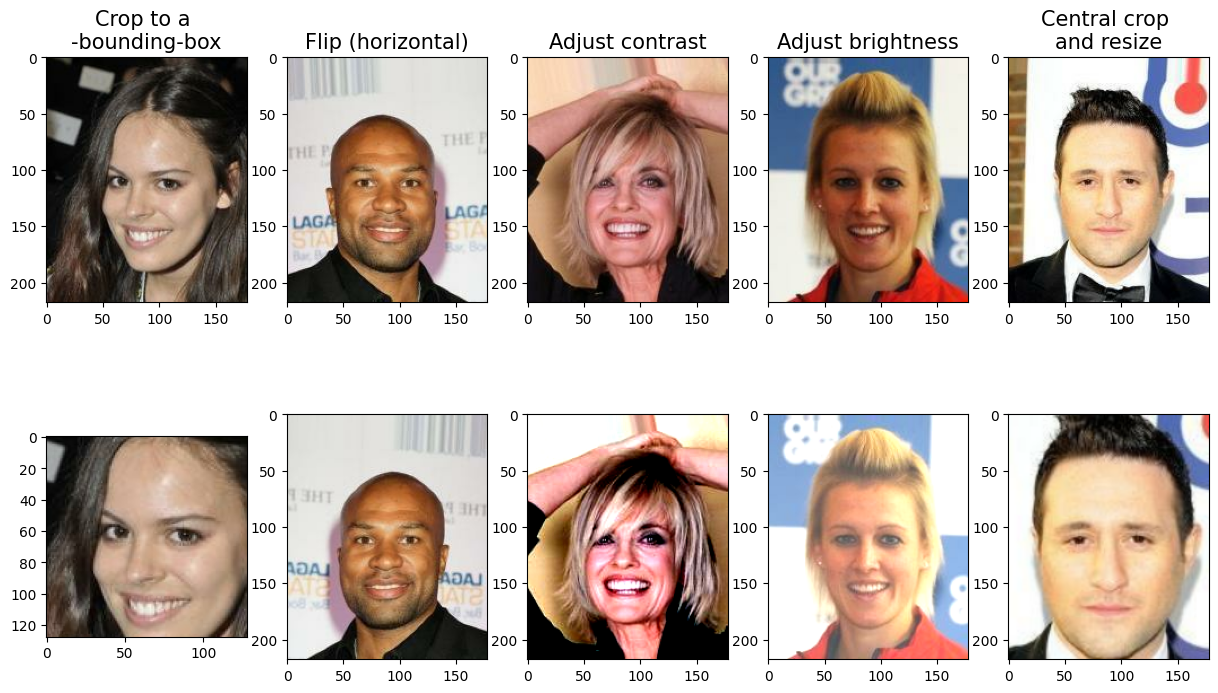

In [7]:
# data augmentation
# uses this when dealing with cases where traing data is limited, some augemntation let us modify or synthesize more data
# and boost the perfomance by reducing overfitting
# examples as cropping parts of an image, flipping, changing contrast, brightness, and saturation
# will here apply five examples
'''
1) cropping an image to a bounding box
2) flipping and image horizontally
3) adjusting the contrast
4) adjusting the britghtness
5) center-cropping and image adn resizing the resulting image back to its original size (218, 178)
'''

import matplotlib.pyplot as plt

# take 5 examples
examples = []
for example in celeba_train.take(5):
    examples.append(example['image'])

fig = plt.figure(figsize=(15, 8.5))

# column 1: cropping to a bounding box
ax = fig.add_subplot(2, 5, 1)
ax.set_title('Crop to a \n-bounding-box', size=15)
ax.imshow(examples[0])
ax = fig.add_subplot(2, 5, 6)
img_cropped = tf.image.crop_to_bounding_box(examples[0], 50, 20, 128, 128)
ax.imshow(img_cropped)


# column 2: flipping (horizontally)
ax = fig.add_subplot(2, 5, 2)
ax.set_title('Flip (horizontal)', size=15)
ax.imshow(examples[1])
ax = fig.add_subplot(2, 5, 7)
img_flipped = tf.image.flip_left_right(examples[1])
ax.imshow(img_flipped)

# column 3: adjust contrast
ax = fig.add_subplot(2, 5, 3)
ax.set_title('Adjust contrast', size=15)
ax.imshow(examples[2])
ax = fig.add_subplot(2, 5, 8)
img_adj_contrast = tf.image.adjust_contrast(examples[2], contrast_factor=2)
ax.imshow(img_adj_contrast)

# column 4: adjust birghtness
ax = fig.add_subplot(2, 5, 4)
ax.set_title('Adjust brightness', size=15)
ax.imshow(examples[3])
ax = fig.add_subplot(2, 5, 9)
img_adj_brightness = tf.image.adjust_brightness(examples[3], delta=0.3)
ax.imshow(img_adj_brightness)

# column 5: cropping from imgae center
ax = fig.add_subplot(2, 5, 5)
ax.set_title('Central crop \nand resize', size=15)
ax.imshow(examples[4])
ax = fig.add_subplot(2, 5, 10)
img_center_cropped = tf.image.central_crop(examples[4], 0.7)
img_resized = tf.image.resize(img_center_cropped, size=(218, 178))
ax.imshow(img_resized.numpy().astype('uint8'))

plt.show()

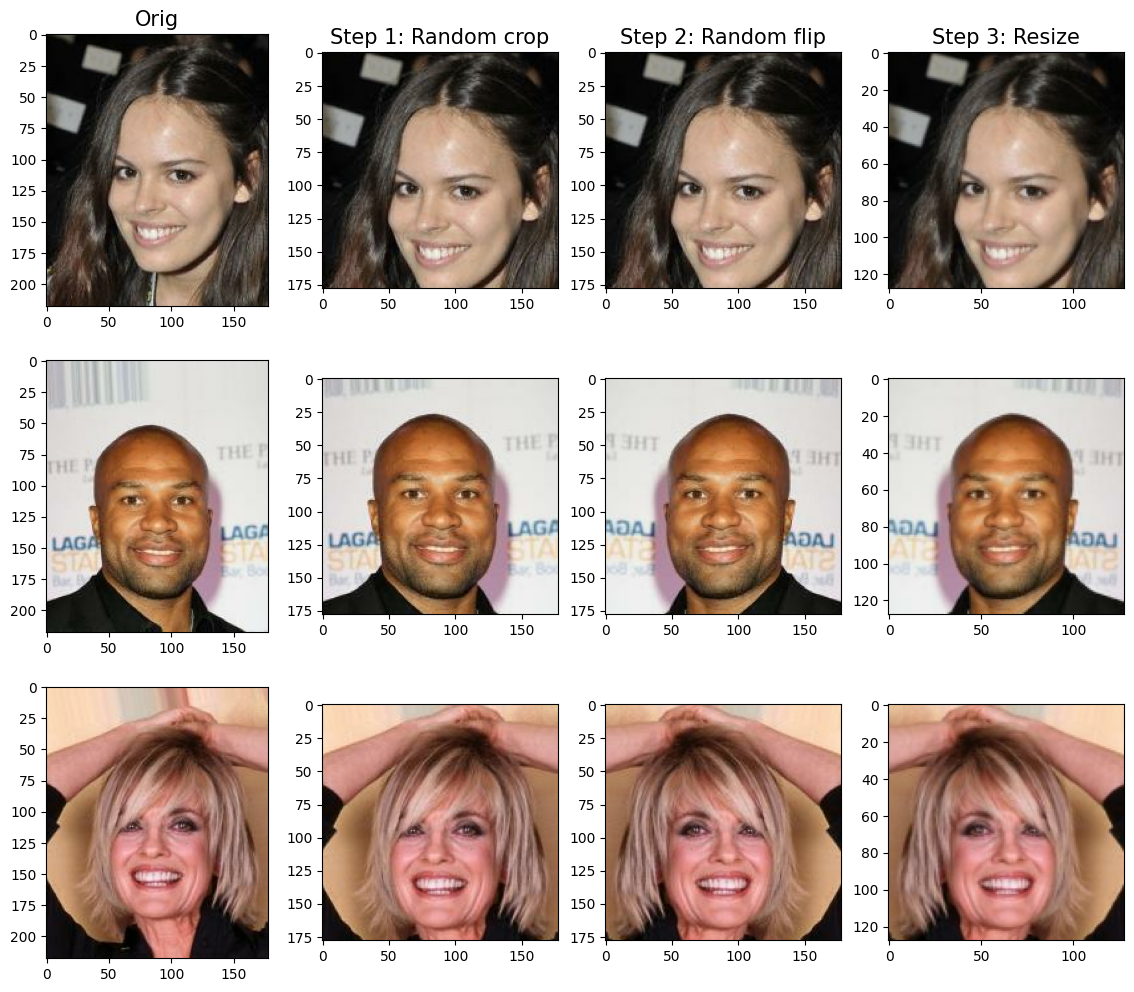

In [8]:
# in previous code block are deterministic
# the transformation canl also be randomized, which is recommended for data augmentation during model training
# we can create a pipeline for these transformations
# we can first randomly crop an image, then flip randomly, and finally, resize it to the desired size
# set random seed for reproducibility

tf.random.set_seed(1)

fig = plt.figure(figsize=(14,12))

for i, example in enumerate(celeba_train.take(3)):
    image = example['image']

    ax = fig.add_subplot(3, 4, i*4+1)
    ax.imshow(image)
    if i == 0:
        ax.set_title('Orig', size=15)

    ax = fig.add_subplot(3, 4, i*4+2)
    img_crop = tf.image.random_crop(image, size=(178,178,3))
    ax.imshow(img_crop)
    if i == 0:
        ax.set_title('Step 1: Random crop', size=15)

    ax = fig.add_subplot(3, 4, i*4+3)
    img_flip = tf.image.random_flip_left_right(img_crop)
    ax.imshow(tf.cast(img_flip, tf.uint8))
    if i == 0:
        ax.set_title('Step 2: Random flip', size=15)

    ax = fig.add_subplot(3, 4, i*4 +4)
    img_resize = tf.image.resize(img_flip, size=(128, 128))
    ax.imshow(tf.cast(img_resize, tf.uint8))
    if i == 0:
        ax.set_title('Step 3: Resize', size=15)

plt.show()